# Capstone — mirrors your deployed research paper

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/h0pi/flyrank-ml-intenrship/blob/main/work/notebooks/capstone.ipynb?flush_cache=true)

This skeleton is yours to fill. Work the sections **in order** — each one has a one-line hint. Simple words, honest numbers.

> Working with an AI assistant? Tell it to read `skills/README.md` first and load the one skill this assignment names on its card.

## 1. Question

*The research question and the decision it supports.*

**Question:** on a given Monday, which content pages are most likely to lose search visibility over the next two weeks, so a content team can look at them first?

- **Unit:** one page (content item) of one client.
- **Decision moment:** 16 March 2026. Everything the model sees is known by then (1–15 March).
- **Output:** a ranked review queue with a reason and a suggested action per page.
- **Who acts:** a content editor, in a weekly review of a few dozen pages.
- **Cost of a wrong call:** a false alarm costs ~20 minutes of review; a missed decline means traffic slips for weeks before anyone notices.

The research question is predictive and operational (*where to look first*), not causal (*what makes pages decline*). That choice shapes every claim below.

In [1]:

QUESTION = "Which content pages are most likely to lose search visibility in the next 16 days?"
DECISION_DATE = "2026-03-16"
print(QUESTION, "| decision moment:", DECISION_DATE)


Which content pages are most likely to lose search visibility in the next 16 days? | decision moment: 2026-03-16


## 2. Data

*Which release, which tables, date windows, what you excluded and why. Public-safe.*

- **Source:** the FlyRank ML Internship warehouse on Hugging Face (`FlyRank/internship-warehouse`), read with DuckDB straight from the Parquet files.
- **Tables:** `fact_content_daily_performance` (one row per page per day: Search Console impressions, clicks, position) and `dim_content` (page type and creation date).
- **Release / window:** the March 2026 partition: 9,841,378 daily rows, 55 clients, 331,437 pages (week-3 data contract). Search Console data is present on 36.7% of those rows.
- **Exclusions, and why:**
  - rows without Search Console data (`gsc_data_available` false): the label is built from impressions;
  - pages with fewer than 100 impressions in 1–15 March: too little traffic for a 20% drop to mean anything;
  - pages created on or after 1 March: no full history before the decision moment.
- **Result:** 74,377 pages from 36 clients. Clients and pages are pseudonymous hashes and are used only for grouping, never as features. No client names, URLs or search queries appear in this work.

In [2]:

%pip -q install duckdb huggingface_hub scikit-learn

import os, json, getpass
from pathlib import Path
import duckdb
import numpy as np
import pandas as pd
import sklearn
from sklearn.model_selection import GroupKFold
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import roc_auc_score
from sklearn.inspection import permutation_importance

SEED = 42
pd.set_option("display.width", 180)

def hf_token():
    tok = os.environ.get("HF_TOKEN")
    if not tok:
        try:
            from google.colab import userdata
            tok = userdata.get("HF_TOKEN")
        except Exception:
            pass
    if not tok:
        try:
            from huggingface_hub import get_token
            tok = get_token()
        except Exception:
            pass
    return tok or getpass.getpass("Hugging Face READ token: ")

ROOT = Path.cwd().parents[1] if Path.cwd().name == "notebooks" else Path.cwd()
OUT = ROOT / "work" / "outputs"
OUT.mkdir(parents=True, exist_ok=True)
CACHE = OUT / "march_pages.parquet"          # same cache file as week 4

if not CACHE.exists():
    con = duckdb.connect()
    con.execute(f"CREATE OR REPLACE SECRET hf (TYPE huggingface, TOKEN '{hf_token()}')")
    REL = "hf://datasets/FlyRank/internship-warehouse"
    con.sql(f"""
        WITH d AS (
            SELECT client_hash_id, content_hash_id, report_date, gsc_impressions, gsc_clicks, gsc_avg_position
            FROM read_parquet('{REL}/fact_content_daily_performance/month=2026-03/*.parquet')
            WHERE gsc_data_available IS TRUE
        ),
        p AS (
            SELECT client_hash_id, content_hash_id,
                   SUM(gsc_impressions) FILTER (WHERE report_date <= DATE '2026-03-15')                            AS imp_h1,
                   SUM(gsc_clicks)      FILTER (WHERE report_date <= DATE '2026-03-15')                            AS clk_h1,
                   SUM(gsc_impressions) FILTER (WHERE report_date <= DATE '2026-03-07')                            AS imp_w1,
                   SUM(gsc_impressions) FILTER (WHERE report_date BETWEEN DATE '2026-03-08' AND DATE '2026-03-15') AS imp_w2,
                   SUM(gsc_avg_position * gsc_impressions)
                       FILTER (WHERE report_date <= DATE '2026-03-15' AND gsc_impressions > 0 AND gsc_avg_position > 0) AS pos_x_imp,
                   SUM(gsc_impressions)
                       FILTER (WHERE report_date <= DATE '2026-03-15' AND gsc_impressions > 0 AND gsc_avg_position > 0) AS imp_with_pos,
                   SUM(gsc_impressions) FILTER (WHERE report_date >= DATE '2026-03-16')                            AS imp_h2
            FROM d GROUP BY 1, 2
            HAVING SUM(gsc_impressions) FILTER (WHERE report_date <= DATE '2026-03-15') >= 100
        )
        SELECT p.*, c.content_created_date, c.content_type
        FROM p JOIN read_parquet('{REL}/dim_content.parquet') c USING (client_hash_id, content_hash_id)
        WHERE c.content_created_date < DATE '2026-03-01'
    """).df().to_parquet(CACHE)

df = pd.read_parquet(CACHE).sort_values(["client_hash_id", "content_hash_id"]).reset_index(drop=True)
df["imp_h2"] = df["imp_h2"].fillna(0)
# ---- inputs: all knowable on 2026-03-16 ----
df["imp_per_day"]   = df["imp_h1"] / 15
df["log_imp"]       = np.log1p(df["imp_per_day"])
df["momentum"]      = np.log((df["imp_w2"].fillna(0) / 8 + 1) / (df["imp_w1"].fillna(0) / 7 + 1))
df["ctr"]           = df["clk_h1"] / df["imp_h1"]
df["avg_position"]  = df["pos_x_imp"] / df["imp_with_pos"]
df["age_days"]      = (pd.Timestamp("2026-03-15") - pd.to_datetime(df["content_created_date"])).dt.days
df["is_feedly"]     = (df["content_type"] == "feedly article").astype(int)
df["is_comparison"] = (df["content_type"] == "comparison article").astype(int)
# ---- label: 16-31 March, used only as the target ----
df["is_declining"]  = ((df["imp_h2"] / 16) < 0.8 * df["imp_per_day"]).astype(int)

FEATURES = ["log_imp", "momentum", "ctr", "avg_position", "age_days", "is_feedly", "is_comparison"]
assert df[FEATURES].notna().all().all()
# week-4 baseline rule, frozen exactly as it was
df["baseline_score"] = np.where(df["momentum"] < -0.1, -df["momentum"] * np.log1p(df["imp_per_day"]), 0.0)

print(f"pages: {len(df):,} | clients: {df.client_hash_id.nunique()} | base rate: {df.is_declining.mean():.3f}")
print(f"scikit-learn {sklearn.__version__} | seed {SEED}")


Note: you may need to restart the kernel to use updated packages.


pages: 74,377 | clients: 36 | base rate: 0.336
scikit-learn 1.9.1 | seed 42


In [3]:

# The frame in numbers (all public-safe aggregates)
top_client_share = df.client_hash_id.value_counts(normalize=True)
data_facts = {
    "march_daily_rows": 9_841_378, "march_clients": 55, "march_pages": 331_437,   # week-3 data contract
    "frame_pages": int(len(df)), "frame_clients": int(df.client_hash_id.nunique()),
    "base_rate": round(float(df.is_declining.mean()), 4),
    "largest_client_share": round(float(top_client_share.iloc[0]), 3),
    "top3_client_share": round(float(top_client_share.iloc[:3].sum()), 3),
    "pages_zero_impressions_after": int((df.imp_h2 == 0).sum()),
    "content_types": df.content_type.value_counts().to_dict(),
}
for k, v in data_facts.items():
    print(f"{k:30} {v}")


march_daily_rows               9841378
march_clients                  55
march_pages                    331437
frame_pages                    74377
frame_clients                  36
base_rate                      0.3359
largest_client_share           0.236
top3_client_share              0.56
pages_zero_impressions_after   131
content_types                  {'keyword article': 73308, 'feedly article': 546, 'comparison article': 523}


## 3. Methodology

*Assumptions, features, label definition, baseline, validation design, leakage checks.*

**Label (one sentence):** a page is *declining* if its average daily impressions on 16–31 March are below 80% of its average on 1–15 March. Base rate: 33.6%.

**Features** (all from 1–15 March or from page metadata):

| Feature | Meaning |
|---|---|
| `log_imp` | log of impressions per day (how visible the page is) |
| `momentum` | log ratio of daily impressions in 8–15 March vs 1–7 March (is it already sliding?) |
| `ctr` | clicks / impressions |
| `avg_position` | impression-weighted average Google position |
| `age_days` | days since the page was created |
| `is_feedly`, `is_comparison` | content type flags |

**Left out on purpose:** client and page ids (grouping only), anything from 16–31 March, and any trend/“direction” field computed by the warehouse (they are derived from the label window).

**Baseline (week 4, frozen):** `score = −momentum × log(1 + impressions/day)` if momentum < −0.1, else 0. No training, so it cannot overfit.

**Model (week 5):** standardized Logistic Regression. Gradient Boosting was also tried; it was not clearly better and is harder to explain.

**Validation:** 5-fold cross-validation **grouped by client** (`GroupKFold`): every test fold contains only clients the model never saw. A random split is shown next to it to measure how much a careless split would flatter the result.

**Assumptions:** the 16-day window is long enough to see a drop and short enough to act on; a 20% drop is a meaningful threshold; March is not unusual (unverified — one month only).

**Leakage checks:** (1) every feature was checked to come from 1–15 March; (2) a deliberate leak (a feature built from the label window) is added below to prove the pipeline would catch it — if it did *not* jump to near-perfect, the check would be broken.

In [4]:

from sklearn.model_selection import KFold
from sklearn.metrics import roc_auc_score

y = df.is_declining.values
folds = list(GroupKFold(n_splits=5).split(df, y, df.client_hash_id))
fold_info = pd.DataFrame([{"fold": i, "test_pages": len(te), "test_clients": df.client_hash_id.iloc[te].nunique(),
                           "test_base_rate": round(y[te].mean(), 3)} for i, (tr, te) in enumerate(folds)])
print(fold_info.to_string(index=False))

def lr():
    return make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000))

def oof(make, cols, splits):
    s = np.zeros(len(df))
    for tr, te in splits:
        s[te] = make().fit(df.iloc[tr][cols], y[tr]).predict_proba(df.iloc[te][cols])[:, 1]
    return s

# Leakage check: a feature built from the label window must look "too good"
df["LEAK_future_ratio"] = np.log((df.imp_h2 / 16 + 1) / (df.imp_per_day + 1))
leak_auc = roc_auc_score(y, oof(lr, FEATURES + ["LEAK_future_ratio"], folds))
df = df.drop(columns="LEAK_future_ratio")
print(f"\nwith deliberate leak: ROC-AUC {leak_auc:.3f}  <- caught, feature removed")


 fold  test_pages  test_clients  test_base_rate
    0       17562             1           0.350
    1       14151             9           0.431
    2       14150            11           0.418
    3       14153             8           0.233
    4       14361             7           0.245



with deliberate leak: ROC-AUC 1.000  <- caught, feature removed


## 4. Results (vs baseline)

*Model vs baseline on the same split. The honest table.*

All numbers below are **out-of-fold**: each page is scored by a model that never saw its client. Precision@K = share of the top-K ranked pages that actually declined; the base rate (random pick) is 0.336.

In [5]:

scores = {
    "Logistic Regression": oof(lr, FEATURES, folds),
    "Gradient Boosting": oof(lambda: HistGradientBoostingClassifier(random_state=SEED), FEATURES, folds),
    "Week-4 rule": df.baseline_score.values,
}
random_split = list(KFold(5, shuffle=True, random_state=SEED).split(df))
lr_random_auc = roc_auc_score(y, oof(lr, FEATURES, random_split))

KS = [10, 25, 50, 100, 200, 500, 1000, 2000, 5000]
def p_at(s, k):
    return y[np.argsort(-s, kind="stable")[:k]].mean()

rows = []
for name, s in scores.items():
    fold_auc = [roc_auc_score(y[te], s[te]) for _, te in folds]
    fold_p50 = [y[te][np.argsort(-s[te], kind="stable")[:50]].mean() for _, te in folds]
    rows.append({"method": name, "ROC-AUC": roc_auc_score(y, s), "AUC fold sd": np.std(fold_auc),
                 "P@50 per fold (mean)": np.mean(fold_p50), **{f"P@{k}": p_at(s, k) for k in (50, 500, 1000, 5000)}})
rows.append({"method": "Random pick (base rate)", "ROC-AUC": 0.5, **{f"P@{k}": y.mean() for k in (50, 500, 1000, 5000)}})
results = pd.DataFrame(rows).set_index("method").round(3)
print(results.to_string())
print(f"\nsame model, RANDOM split: ROC-AUC {lr_random_auc:.3f}  vs grouped {results.loc['Logistic Regression', 'ROC-AUC']:.3f}")


                         ROC-AUC  AUC fold sd  P@50 per fold (mean)   P@50  P@500  P@1000  P@5000
method                                                                                           
Logistic Regression        0.658        0.048                 0.912  0.980  0.880   0.825   0.663
Gradient Boosting          0.662        0.033                 0.884  0.900  0.854   0.802   0.659
Week-4 rule                0.633        0.047                 0.864  0.980  0.832   0.779   0.639
Random pick (base rate)    0.500          NaN                   NaN  0.336  0.336   0.336   0.336

same model, RANDOM split: ROC-AUC 0.697  vs grouped 0.658


In [6]:

# Inside the harder group: pages already sliding but not collapsed (where a refresh decision is made)
df["score"] = scores["Logistic Regression"]
df["archetype"] = np.select([df.momentum < -1.5, df.age_days < 45, df.momentum < -0.1,
                             (df.avg_position <= 10) & (df.ctr < df.loc[df.avg_position <= 10, "ctr"].median())],
                            ["cliff_drop", "new_page_settling", "sliding_visible", "low_ctr_page_one"], "stable")
rv = df[df.archetype == "sliding_visible"]
refresh = pd.DataFrame({k: {"model": rv.sort_values("score", ascending=False).is_declining.head(k).mean(),
                            "rule": rv.sort_values("baseline_score", ascending=False).is_declining.head(k).mean(),
                            "random": rv.is_declining.mean()} for k in (50, 100, 500)}).T.round(3)
print(f"refresh-candidate pages: {len(rv):,}")
print(refresh.to_string())

# What drives the score: AUC drop when one feature is shuffled (grouped folds, mean over folds)
from sklearn.inspection import permutation_importance
imp = []
for tr, te in folds:
    m = lr().fit(df.iloc[tr][FEATURES], y[tr])
    r = permutation_importance(m, df.iloc[te][FEATURES], y[te], scoring="roc_auc", n_repeats=3, random_state=SEED)
    imp.append(r.importances_mean)
importance = pd.Series(np.mean(imp, axis=0), index=FEATURES).sort_values(ascending=False).round(3)
print("\nROC-AUC drop when shuffled:")
print(importance.to_string())


refresh-candidate pages: 28,756
     model  rule  random
50   0.780  0.58   0.424
100  0.730  0.58   0.424
500  0.684  0.63   0.424



ROC-AUC drop when shuffled:
momentum         0.121
ctr              0.028
age_days         0.021
avg_position     0.005
is_feedly        0.001
is_comparison    0.000
log_imp         -0.004


**Reading the results**
- At the very top (K ≤ 100) model and rule tie: both pick pages that already collapsed, which is easy. The model pulls ahead from K = 500 on and in ROC-AUC (0.658 vs 0.633).
- Among pages that are only *sliding* (the refresh decisions), the model's top 50 declined clearly more often than the rule's (see table above): this is where the model earns its place.
- The random split reads about 0.04 AUC higher than the grouped one: pages of the same client share trends, so a random split partly tests memory of the client.
- `momentum` carries most of the signal; CTR and age add a little; content type and position almost nothing.

## 5. Limitations

*What this work cannot claim.*

- **One month.** Trained and evaluated on March 2026 only; no second month was available as a sealed test. Seasonality or a Google update could change the base rate and the ranking quality.
- **Association, not cause.** Nothing here shows that refreshing a page *causes* recovery. No refresh was observed in the data.
- **Easy top.** The best precision numbers come from pages that already collapsed; part of that is "down stays down". The fair test is the refresh group and the ROC-AUC, both modest (0.66).
- **Label = impressions.** It ignores clicks, conversions and whether the page still matters to the business.
- **Client concentration.** One client is 23.6% of the pages and the top three are 56%; per-fold AUC varies (sd ≈ 0.05).
- **Not calibrated.** The score ranks pages; it is not a probability for one page.
- **Possible tracking artefacts.** 131 pages had zero impressions after 16 March; some may be tracking or de-indexing, not decay. They are labelled declining.

In [7]:

# Error analysis for the limitations: what do the model's top-500 false alarms look like?
top500 = df.sort_values("score", ascending=False).head(500)
fa = top500[top500.is_declining == 0]
print(f"false alarms in the model's top 500: {len(fa)} ({len(fa) / 500:.0%})")
print(f"  median impressions/day: {fa.imp_per_day.median():.0f} (all top-500: {top500.imp_per_day.median():.0f})")
print(f"  share with a sharp week-2 drop (momentum < -1.5): {(fa.momentum < -1.5).mean():.0%}")
print(f"per-fold ROC-AUC of the model: {[round(roc_auc_score(y[te], df.score.values[te]), 3) for _, te in folds]}")


false alarms in the model's top 500: 60 (12%)
  median impressions/day: 18 (all top-500: 22)
  share with a sharp week-2 drop (momentum < -1.5): 88%
per-fold ROC-AUC of the model: [0.67, 0.737, 0.59, 0.681, 0.65]


## 6. Ranked recommendations

*The action playbook output — the paper's recommendations section.*

The week-7 playbook turns the score into a weekly routine. Every page gets one archetype (checked in order) and one action; each action is its own lane, sorted by the model score:

1. **Technical check first** (`cliff_drop`, daily impressions fell below ~22% within a week): check indexing, redirects and tracking. Top 20 per week, ~5 minutes each.
2. **Refresh review** (`sliding_visible`, momentum below −0.1): open the page and decide on a content refresh. Top 30 per week, ~20 minutes each.
3. **Snippet fix** (`low_ctr_page_one`, page-one position but CTR below the page-one median): rewrite title and meta description. Top 10 per week.
4. **Wait** (`new_page_settling`, younger than 45 days) and **monitor** (everything else).

A person checks every page before acting; nothing is edited, unpublished or redirected automatically, and the score is never used to judge writers or clients.

In [8]:

ACTION = {"cliff_drop": "check_technical", "sliding_visible": "review_refresh", "low_ctr_page_one": "fix_snippet",
          "new_page_settling": "monitor", "stable": "monitor"}
df["action"] = df.archetype.map(ACTION)
LANES = {"check_technical": 20, "review_refresh": 30, "fix_snippet": 10}
weekly = pd.concat([df[df.action == a].sort_values("score", ascending=False).head(n) for a, n in LANES.items()])
lanes = (weekly.groupby("action", sort=False).agg(pages=("score", "size"), declined=("is_declining", "mean"))
         .assign(lane_base_rate=lambda t: [df.loc[df.action == a, "is_declining"].mean() for a in t.index]).round(3))
archetypes = (df.groupby("archetype").agg(pages=("is_declining", "size"), declined=("is_declining", "mean"))
              .loc[["cliff_drop", "sliding_visible", "new_page_settling", "low_ctr_page_one", "stable"]].round(3))
print(lanes.to_string())
print()
print(archetypes.to_string())


                 pages  declined  lane_base_rate
action                                          
check_technical     20     1.000           0.864
review_refresh      30     0.833           0.424
fix_snippet         10     0.300           0.273

                   pages  declined
archetype                         
cliff_drop           867     0.864
sliding_visible    28756     0.424
new_page_settling   8998     0.307
low_ctr_page_one    9984     0.273
stable             25772     0.254


## 7. Artifacts the paper embeds

*Generate/collect the charts and tables your deployed page will show.*

Charts go to `docs/img/` (served with the paper); all numbers go to `work/outputs/capstone_metrics.json`. The page itself is built from that JSON by `work/paper/build_paper.py`, so the paper's numbers always match a fresh run.

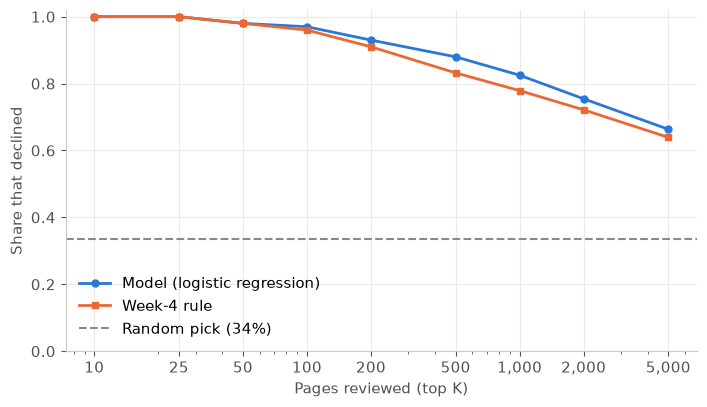

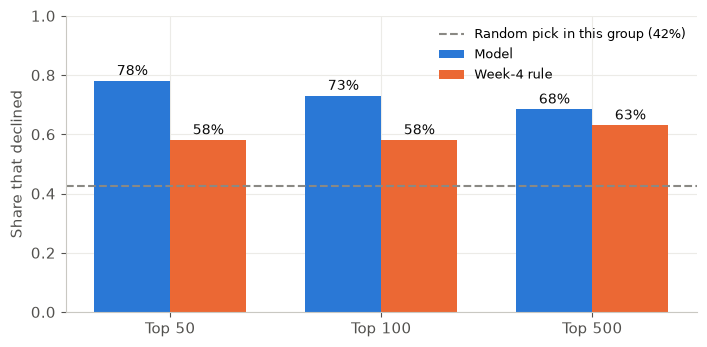

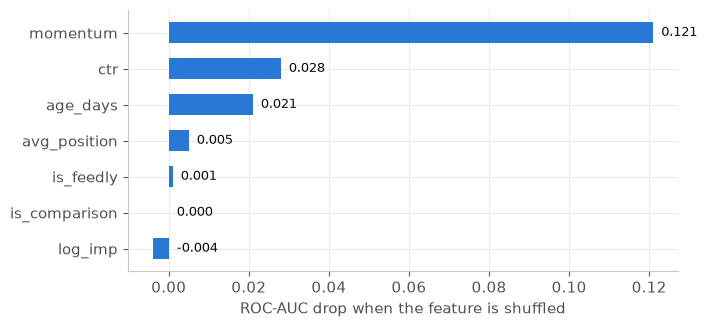

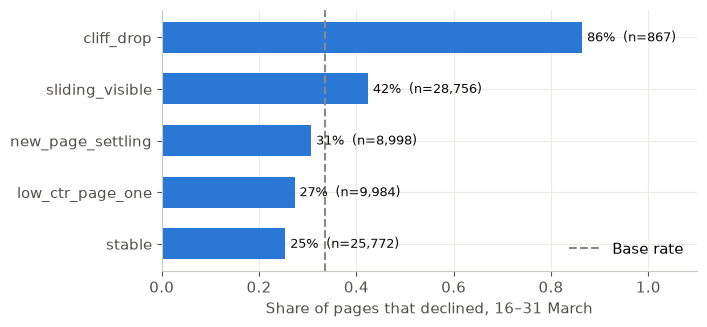

wrote capstone_metrics.json and ['fig1_precision_at_k.png', 'fig2_refresh_group.png', 'fig3_importance.png', 'fig4_archetypes.png']


In [9]:

import matplotlib.pyplot as plt
%matplotlib inline
IMG = ROOT / "docs" / "img"
IMG.mkdir(parents=True, exist_ok=True)
BLUE, ORANGE, GREY, INK, MUTED = "#2a78d6", "#eb6834", "#8a8984", "#0b0b0b", "#52514e"
plt.rcParams.update({"font.size": 11, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.edgecolor": "#c9c8c2", "axes.labelcolor": MUTED, "xtick.color": MUTED, "ytick.color": MUTED,
                     "axes.grid": True, "axes.axisbelow": True, "grid.color": "#ecebe7", "grid.linewidth": 0.8})

# Figure 1: precision@K, model vs rule vs random
fig, ax = plt.subplots(figsize=(7.2, 4.2))
ax.plot(KS, [p_at(scores["Logistic Regression"], k) for k in KS], color=BLUE, lw=2, marker="o", ms=5, label="Model (logistic regression)")
ax.plot(KS, [p_at(scores["Week-4 rule"], k) for k in KS], color=ORANGE, lw=2, marker="s", ms=5, label="Week-4 rule")
ax.axhline(y.mean(), color=GREY, lw=1.5, ls="--", label=f"Random pick ({y.mean():.0%})")
ax.set_xscale("log"); ax.set_ylim(0, 1.02); ax.set_xticks(KS); ax.set_xticklabels([f"{k:,}" for k in KS])
ax.set_xlabel("Pages reviewed (top K)"); ax.set_ylabel("Share that declined")
ax.legend(frameon=False, loc="lower left"); fig.tight_layout()
fig.savefig(IMG / "fig1_precision_at_k.png", dpi=200); plt.show()

# Figure 2: refresh group, top 50/100/500
fig, ax = plt.subplots(figsize=(7.2, 3.6))
x = np.arange(3); w = 0.36
ax.bar(x - w / 2, refresh["model"], w, color=BLUE, label="Model")
ax.bar(x + w / 2, refresh["rule"], w, color=ORANGE, label="Week-4 rule")
ax.axhline(rv.is_declining.mean(), color=GREY, lw=1.5, ls="--", label=f"Random pick in this group ({rv.is_declining.mean():.0%})")
for i, k in enumerate(refresh.index):
    ax.text(i - w / 2, refresh.loc[k, "model"] + 0.02, f"{refresh.loc[k, 'model']:.0%}", ha="center", color=INK, fontsize=10)
    ax.text(i + w / 2, refresh.loc[k, "rule"] + 0.02, f"{refresh.loc[k, 'rule']:.0%}", ha="center", color=INK, fontsize=10)
ax.set_xticks(x); ax.set_xticklabels([f"Top {k}" for k in refresh.index]); ax.set_ylim(0, 1)
ax.set_ylabel("Share that declined"); ax.legend(frameon=False, loc="upper right", fontsize=9); fig.tight_layout()
fig.savefig(IMG / "fig2_refresh_group.png", dpi=200); plt.show()

# Figure 3: what the score relies on
fig, ax = plt.subplots(figsize=(7.2, 3.4))
imp_plot = importance.sort_values()
ax.barh(imp_plot.index, imp_plot.values, color=BLUE, height=0.6)
for i, v in enumerate(imp_plot.values):
    ax.text(max(v, 0) + 0.002, i, f"{v:.3f}", va="center", fontsize=9, color=INK)
ax.set_xlabel("ROC-AUC drop when the feature is shuffled"); fig.tight_layout()
fig.savefig(IMG / "fig3_importance.png", dpi=200); plt.show()

# Figure 4: observed decline rate by archetype
fig, ax = plt.subplots(figsize=(7.2, 3.4))
a_plot = archetypes.iloc[::-1]
ax.barh(a_plot.index, a_plot.declined, color=BLUE, height=0.6)
ax.axvline(y.mean(), color=GREY, lw=1.5, ls="--", label="Base rate")
for i, (a, r) in enumerate(a_plot.iterrows()):
    ax.text(r.declined + 0.01, i, f"{r.declined:.0%}  (n={r.pages:,.0f})", va="center", fontsize=9, color=INK)
ax.set_xlim(0, 1.1); ax.set_xlabel("Share of pages that declined, 16–31 March"); ax.legend(frameon=False, loc="lower right")
fig.tight_layout(); fig.savefig(IMG / "fig4_archetypes.png", dpi=200); plt.show()

metrics = {
    "question": QUESTION, "decision_date": DECISION_DATE, "seed": SEED, "sklearn": sklearn.__version__,
    "data": data_facts, "folds": fold_info.to_dict(orient="records"),
    "leak_check_auc": round(float(leak_auc), 3), "random_split_auc": round(float(lr_random_auc), 3),
    "results": {m: {k: (None if pd.isna(v) else float(v)) for k, v in r.items()} for m, r in results.iterrows()},
    "precision_curve": {m: {str(k): round(float(p_at(scores[m], k)), 3) for k in KS} for m in ["Logistic Regression", "Week-4 rule"]},
    "refresh_group": {"pages": int(len(rv)), "base_rate": round(float(rv.is_declining.mean()), 3),
                      "top": {str(k): {"model": float(r.model), "rule": float(r.rule)} for k, r in refresh.iterrows()}},
    "importance_auc_drop": importance.to_dict(),
    "false_alarms_top500": int(len(fa)),
    "archetypes": {a: {"pages": int(r.pages), "declined": float(r.declined)} for a, r in archetypes.iterrows()},
    "lanes": {a: {"pages": int(r.pages), "declined": float(r.declined), "lane_base_rate": float(r.lane_base_rate)} for a, r in lanes.iterrows()},
}
(OUT / "capstone_metrics.json").write_text(json.dumps(metrics, indent=2))
print("wrote", (OUT / "capstone_metrics.json").name, "and", sorted(p.name for p in IMG.glob("*.png")))


## ML-12: 5-minute demo outline (Week-8 showcase)

Paper: https://h0pi.github.io/flyrank-ml-intenrship/

1. **Question (45 s).** FlyRank publishes and maintains content for many clients; pages that rank slowly decay. Out of thousands of pages, which should a person look at first? Concretely: which pages will lose Google impressions in the next 16 days?
2. **Method (75 s).** One month of real Search Console data: 74,377 pages from 36 clients, decision moment 16 March 2026. Label: daily impressions in 16–31 March below 80% of 1–15 March (base rate 34%). A frozen “already sliding × traffic” rule vs a logistic regression on seven features, cross-validated on clients the model never saw, plus a deliberate-leak check (AUC jumps to 1.0, so the check works).
3. **One chart (60 s).** Figure 2 of the paper: among pages that are only starting to slide, the model's top 50 declined 78% of the time, the rule's 58%, a random pick 42%.
4. **One honest result (60 s).** At the very top both methods tie (98% of the top 50), because pages that already collapsed stay down; the model's real gain is in the next tier, and overall it is modest (ROC-AUC 0.66 vs 0.63). One month only, and associations, not causes.
5. **One recommendation (60 s).** Review in lanes, not one list: each week, 20 quick technical checks for sharp drops, 30 refresh reviews for sliding pages ranked by the model, 10 snippet fixes. A person confirms every drop; nothing is changed automatically.

## ML-12: two shareable cuts

**Social post (methodology)**
> Which pages will lose Google visibility in the next two weeks? I tested it on one month of real search data: 74k content pages from 36 sites. The honest part is the setup: a simple rule as the baseline, a model validated only on sites it had never seen, and a deliberately leaky feature to prove the leak check works. Result: at the top of the list the simple rule is as good as the model; among pages that are only starting to slide, the model's top 50 had 78% real declines vs 58% for the rule (34% at random). Paper and code: https://h0pi.github.io/flyrank-ml-intenrship/

**3-sentence employer summary**
> I built a ranked page-review queue that flags which content pages will lose search impressions in the next 16 days, using 74,377 real pages from 36 client sites (FlyRank ML Internship data, March 2026). I compared a frozen rule baseline with a logistic regression under client-grouped cross-validation, added leakage checks, and reported every result next to the 34% base rate. The model matched the rule at the top of the list and beat it on the harder cases (78% vs 58% real declines in the top 50 sliding pages), and the work ships as a deployed paper with a weekly action playbook.

## Self-check

Before you submit, confirm each line honestly:

- [ ] Every section above is filled — markdown thinking AND the code that backs it
- [ ] The notebook runs top to bottom with no errors (Runtime → Run all)
- [ ] No client names, URLs, or private queries anywhere
- [ ] My claims use careful words: observed, measured, directional, decision-support
- [ ] Committed to my repo under `work/notebooks/` — then submit your repo URL on the card. Done.
- [ ] My deployed paper has **all 9 sections** — including the **Abstract** at the top and **Acknowledgments & data credit** (the https://flyrank.ai link) at the bottom.
- [ ] **ML-12 done in this notebook's closing cells:** 5-minute demo outline + a social-post cut + a 3-sentence employer-facing summary.
